<a href="https://colab.research.google.com/github/allie-tran/202609-csc1159-resources/blob/main/notebooks/names_template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Template to get started exploring names datasets
Allie Tran
allie.tran@dcu.ie    
https://github.com/allie-tran/202609-csc1159-resources

In [27]:
# get the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

## Step 1: Load the Baby Names dataset

The US names dataset (the default on the first line) is the biggest one.  
Uncomment another line to get the UK or Irish baby names datasets (much smaller).

In [28]:
names_df = pd.read_csv("https://raw.githubusercontent.com/allie-tran/202609-csc1159-resources/main/data/names/usnames.csv")
# names_df = pd.read_csv("https://raw.githubusercontent.com/allie-tran/202609-csc1159-resources/main/data/names/irishnames.csv")
# names_df = pd.read_csv("https://raw.githubusercontent.com/allie-tran/202609-csc1159-resources/main/data/names/nswbabynames.csv")
# names_df = pd.read_csv("https://raw.githubusercontent.com/allie-tran/202609-csc1159-resources/main/data/names/uknames.csv")
names_df.head()

,name,sex,births,year
0,Mary,F,7065,1880
1,Anna,F,2604,1880
2,Emma,F,2003,1880
3,Elizabeth,F,1939,1880
4,Minnie,F,1746,1880


In [29]:
names_df.describe()

,births,year
count,2.117219e+06,2.117219e+06
mean,1.741134e+02,1.978991e+03
std,1.473001e+03,3.499572e+01
min,5.000000e+00,1.880000e+03
25%,7.000000e+00,1.956000e+03
50%,1.200000e+01,1.989000e+03
75%,3.200000e+01,2.007000e+03
max,9.969300e+04,2.023000e+03


## Group the names by the year

In [30]:
def add_prop(group):
    # Integer division floors
    births = group.births.astype(float)
    group['prop'] = births / births.sum()
    return group

usn = names_df.groupby(['year', 'sex'], group_keys=False)[["name", "sex", "births", "year"]].apply(add_prop)
usn.head()

,name,sex,births,year,prop
0,Mary,F,7065,1880,0.077642
1,Anna,F,2604,1880,0.028617
2,Emma,F,2003,1880,0.022012
3,Elizabeth,F,1939,1880,0.021309
4,Minnie,F,1746,1880,0.019188


In [31]:
myname = usn[(usn.name == "Allie") & (usn.sex == "F")]
myname.describe()

,births,year,prop
count,144.000000,144.000000,144.000000
mean,362.111111,1951.500000,0.000428
std,399.209518,41.713307,0.000398
min,13.000000,1880.000000,0.000007
25%,86.500000,1915.750000,0.000052
50%,230.500000,1951.500000,0.000328
75%,421.750000,1987.250000,0.000763
max,1636.000000,2023.000000,0.001323


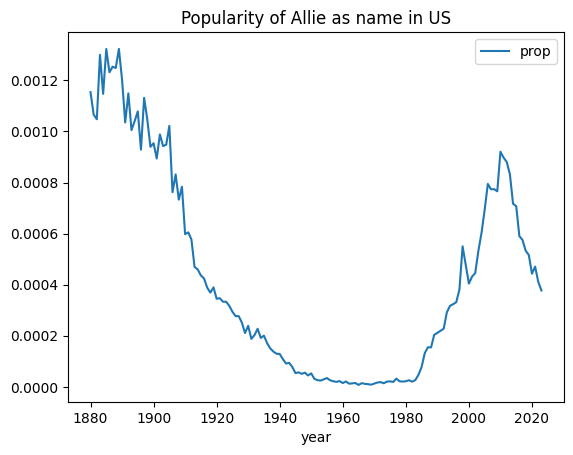

In [36]:
myname.plot(x='year', y='prop', title="Popularity of Allie as name in US")
plt.show()

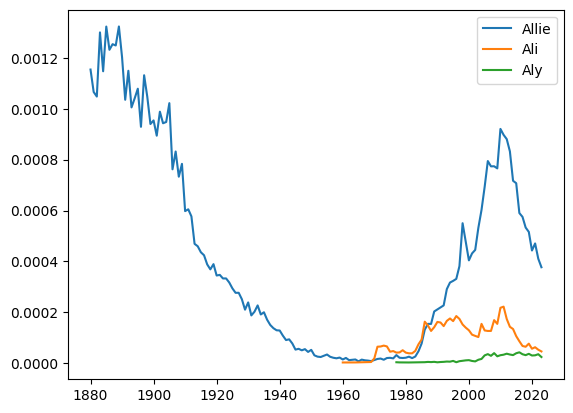

In [44]:
ali = usn[(usn.name == "Ali") & (usn.sex == "F")]
aly = usn[(usn.name == "Aly") & (usn.sex == "F")]

plt.plot(myname.year, myname.prop, label="Allie")
plt.plot(ali.year, ali.prop, label="Ali")
plt.plot(aly.year, aly.prop, label="Aly")
plt.legend(loc='upper right')
plt.show()